# Dynamic Pricing RL — Training Notebook

Trains three reinforcement-learning pricing agents — **DQN**, **QR-DQN** (`sb3-contrib`) and **PPO** —
on the existing **synthetic** dynamic-pricing dataset, and saves the trained artifacts into `backend/models/`.

**Important notes**

- The dataset (`dynamic_pricing_synthetic_dataset.csv`, ~87,600 hourly records) is **100 % synthetic**.
  Every number produced by this notebook is a **synthetic simulation result**, not a real-market outcome,
  and no algorithm is assumed to outperform the others — actual measured results are reported.
- All random seeds are fixed (`SEED = 42`) for reproducibility where practical.
- Training is **sequential and lightweight by default**: `DQN_TIMESTEPS = QRDQN_TIMESTEPS = PPO_TIMESTEPS = 1000`
  (a fast smoke test). Raise the values for stronger agents and rerun.
- All three agents share the same Gymnasium environment, the same demand prediction model, the same
  6-value observation order, the same 5 discrete actions, the same price/reward definition, and the same
  evaluation protocol as each other and as `backend/main.py`.

**Steps:** 1 packages → 2 load/validate data → 3 EDA → 4 leakage-free features → 5 demand model →
6 environment + scaler → 7 training (DQN → QR-DQN → PPO, sequential) → 8 evaluation vs baselines →
9 save artifacts (backup → test → promote) → 10 reload & inference test

## Step 1 — Install / verify required packages

In [1]:
# Step 1: verify required packages; install only what is missing.
import importlib.util
import subprocess
import sys

REQUIRED = {
    "numpy": "numpy",
    "pandas": "pandas",
    "sklearn": "scikit-learn",
    "joblib": "joblib",
    "matplotlib": "matplotlib",
    "gymnasium": "gymnasium",
    "stable_baselines3": "stable-baselines3",
    "sb3_contrib": "sb3-contrib",
}
missing = [pkg for mod, pkg in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing missing packages:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("All required packages already installed:")
for mod, pkg in REQUIRED.items():
    m = importlib.util.find_spec(mod) and __import__(mod)
    print(f"  {pkg:22} {getattr(m, '__version__', '?')}")

All required packages already installed:
  numpy                  2.5.3


  pandas                 3.0.6


  scikit-learn           1.9.1
  joblib                 1.6.0
  matplotlib             3.11.2
  gymnasium              1.3.0


  stable-baselines3      2.9.0
  sb3-contrib            2.9.0


## Step 2 — Configuration, dataset discovery, loading and validation

In [2]:
# Step 2a: configuration -------------------------------------------------------
import json
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Configurable training budgets. 1000 steps = fast smoke test; raise for stronger agents.
DQN_TIMESTEPS = 1_000
QRDQN_TIMESTEPS = 1_000
PPO_TIMESTEPS = 1_000

EVAL_EPISODES = 20        # every strategy is evaluated from identical initial conditions
EVAL_STEPS = 30           # max decision steps per evaluation episode
ENV_EPISODE_STEPS = 30    # max decision steps per training episode
TRAINING_SECONDS = {}     # filled in step 7

def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "backend" / "main.py").exists():
            return candidate
    raise FileNotFoundError(
        "Project root not found (backend/main.py). Run this notebook from the rl_frontend project directory."
    )

PROJECT_ROOT = find_project_root(Path.cwd())
MODELS_DIR = PROJECT_ROOT / "backend" / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Locate the existing synthetic dataset: project root -> parents -> home -> Downloads -> Desktop,
# then a shallow search inside backend/. No dataset is generated or replaced by this notebook.
DATASET_NAME = "dynamic_pricing_synthetic_dataset.csv"
SEARCH_DIRS = [
    PROJECT_ROOT,
    PROJECT_ROOT.parent,
    PROJECT_ROOT.parent.parent,
    Path.home(),
    Path.home() / "Downloads",
    Path.home() / "Desktop",
]
DATASET_PATH = next((d / DATASET_NAME for d in SEARCH_DIRS if (d / DATASET_NAME).exists()), None)
if DATASET_PATH is None:
    for sub in ("backend", "data", "datasets"):
        base = PROJECT_ROOT / sub
        if base.exists():
            hits = sorted(base.rglob(DATASET_NAME))
            if hits:
                DATASET_PATH = hits[0]
                break
assert DATASET_PATH is not None, (
    f"{DATASET_NAME} could not be found. Expected location: one of "
    + ", ".join(str(d / DATASET_NAME) for d in SEARCH_DIRS[:4])
)

print("Project root :", PROJECT_ROOT)
print("Dataset      :", DATASET_PATH)
print("Models dir   :", MODELS_DIR)
print(f"Seed: {SEED} | timesteps: DQN={DQN_TIMESTEPS}, QRDQN={QRDQN_TIMESTEPS}, PPO={PPO_TIMESTEPS}")
print("Data source: SYNTHETIC dataset (all results in this notebook are synthetic simulation results).")

Project root : C:\Users\VENKAT\Desktop\RL_PROJECT\rl_frontend
Dataset      : C:\Users\VENKAT\Downloads\dynamic_pricing_synthetic_dataset.csv
Models dir   : C:\Users\VENKAT\Desktop\RL_PROJECT\rl_frontend\backend\models
Seed: 42 | timesteps: DQN=1000, QRDQN=1000, PPO=1000
Data source: SYNTHETIC dataset (all results in this notebook are synthetic simulation results).


In [3]:
# Step 2b: load and validate ---------------------------------------------------
REQUIRED_COLUMNS = [
    "timestamp", "product_id", "price", "inventory", "competitor_price",
    "demand", "sales", "revenue", "season", "promotion", "conversion_rate",
]
VALID_SEASONS = ["regular", "summer", "monsoon", "festival"]

df = pd.read_csv(DATASET_PATH)
missing_cols = [c for c in REQUIRED_COLUMNS if c not in df.columns]
assert not missing_cols, f"Missing required columns: {missing_cols}. Found: {list(df.columns)}"

df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
numeric_cols = ["price", "inventory", "competitor_price", "demand", "sales", "revenue", "promotion", "conversion_rate"]
for c in numeric_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

rows_before = len(df)
null_rows = int(df[REQUIRED_COLUMNS].isna().any(axis=1).sum())
df = df.dropna(subset=REQUIRED_COLUMNS)

invalid_mask = (
    (df["price"] <= 0)
    | (df["inventory"] < 0)
    | (df["competitor_price"] <= 0)
    | (df["demand"] < 0)
    | (~df["season"].isin(VALID_SEASONS))
    | (~df["promotion"].isin([0, 1]))
)
invalid_rows = int(invalid_mask.sum())
df = df[~invalid_mask]

df = df.sort_values("timestamp").reset_index(drop=True)
assert len(df) > 0, "Dataset is empty after validation."

print(f"Rows read          : {rows_before:,}")
print(f"Rows with nulls    : {null_rows:,} (dropped)")
print(f"Invalid rows       : {invalid_rows:,} (dropped)")
print(f"Valid rows         : {len(df):,} x {df.shape[1]} cols")
print(f"Time range         : {df['timestamp'].min()} -> {df['timestamp'].max()}")
print(f"Products           : {df['product_id'].nunique()} | Seasons: {sorted(df['season'].unique())}")
df.head(3)

Rows read          : 87,600
Rows with nulls    : 0 (dropped)
Invalid rows       : 0 (dropped)
Valid rows         : 87,600 x 11 cols
Time range         : 2025-01-01 00:00:00 -> 2034-12-29 23:00:00
Products           : 20 | Seasons: ['festival', 'monsoon', 'regular', 'summer']


,timestamp,product_id,price,inventory,competitor_price,demand,sales,revenue,season,promotion,conversion_rate
0,2025-01-01 00:00:00,P002,947.55,941,763.62,199,31,29373.92,regular,0,0.1602
1,2025-01-01 01:00:00,P016,1391.31,1813,1442.57,284,43,59826.29,regular,0,0.1519
2,2025-01-01 02:00:00,P014,1442.99,1416,1201.97,269,40,57719.73,regular,0,0.1498


## Step 3 — Brief exploratory data analysis (synthetic data)

          price  inventory  competitor_price    demand     sales    revenue  \
count  87600.00   87600.00          87600.00  87600.00  87600.00   87600.00   
mean    1250.38    1000.58           1250.56    272.02     43.62   54519.36   
std      569.99     578.88            593.15     58.64     11.83   29799.81   
min      448.15       0.00            292.43    108.00      0.00       0.00   
25%      757.65     497.00            742.64    226.00     35.00   31571.82   
50%     1226.87    1002.00           1172.46    272.00     43.00   47979.56   
75%     1550.46    1503.00           1579.83    317.00     52.00   70632.13   
max     3208.55    2000.00           3875.69    457.00    100.00  250016.26   

       conversion_rate  
count         87600.00  
mean              0.16  
std               0.02  
min               0.08  
25%               0.15  
50%               0.16  
75%               0.17  
max               0.26  

Missing values per column (after validation):
timestamp       

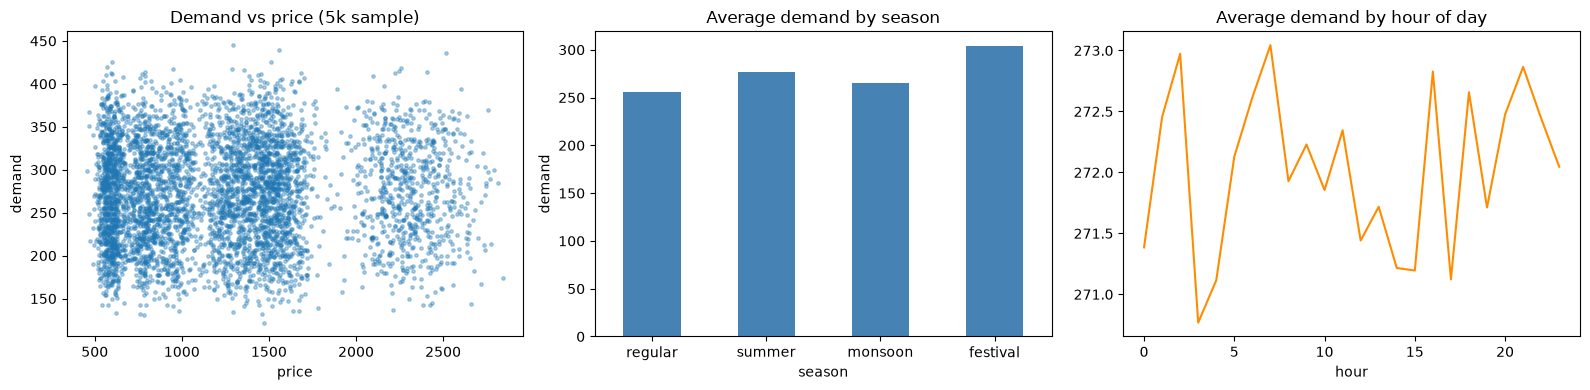

In [4]:
# Step 3: brief EDA ------------------------------------------------------------
%matplotlib inline
import matplotlib.pyplot as plt

print(df[["price", "inventory", "competitor_price", "demand", "sales", "revenue", "conversion_rate"]].describe().round(2))
print("\nMissing values per column (after validation):")
print(df.isna().sum().to_string())
print("\nRows per season:")
print(df["season"].value_counts().to_string())
print("\nPromotion split:")
print(df["promotion"].value_counts().to_string())
print("\nCorrelation of price with demand: "
      f"{df['price'].corr(df['demand']):.3f} | competitor price with demand: {df['competitor_price'].corr(df['demand']):.3f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sample = df.sample(n=min(len(df), 5000), random_state=SEED)
axes[0].scatter(sample["price"], sample["demand"], s=6, alpha=0.35)
axes[0].set_xlabel("price"); axes[0].set_ylabel("demand"); axes[0].set_title("Demand vs price (5k sample)")
df.groupby("season")["demand"].mean().reindex(VALID_SEASONS).plot(kind="bar", ax=axes[1], color="steelblue")
axes[1].set_title("Average demand by season"); axes[1].set_ylabel("demand"); axes[1].tick_params(axis="x", rotation=0)
df.groupby(df["timestamp"].dt.hour)["demand"].mean().plot(ax=axes[2], color="darkorange")
axes[2].set_title("Average demand by hour of day"); axes[2].set_xlabel("hour")
plt.tight_layout(); plt.show()

## Step 4 — Feature preparation without target leakage

**Predictors:** `price`, `competitor_price`, `inventory`, `season`, `promotion`, `hour`, `weekday`
(all known at pricing time and available to `backend/main.py` at inference).

**Excluded to avoid leakage:** `demand` (target), `sales`, `revenue` (both computed from demand),
and `conversion_rate` (a downstream outcome of the same simulation). `product_id` is excluded because
the API receives no product identifier. The split is time-based (first 80 % train / last 20 % test).

In [5]:
# Step 4: leakage-free features + time-based split -----------------------------
df["hour"] = df["timestamp"].dt.hour.astype("int64")
df["weekday"] = df["timestamp"].dt.dayofweek.astype("int64")

MODEL_FEATURES = ["price", "competitor_price", "inventory", "season", "promotion", "hour", "weekday"]
TARGET = "demand"

split_pos = int(len(df) * 0.8)
split_time = df["timestamp"].iloc[split_pos]
train_df = df.iloc[:split_pos].copy()
test_df = df.iloc[split_pos:].copy()
assert len(train_df) > 1000 and len(test_df) > 100, "Split produced too-small partitions."

print(f"Train: {len(train_df):,} rows ({train_df['timestamp'].min()} -> {train_df['timestamp'].max()})")
print(f"Test : {len(test_df):,} rows ({test_df['timestamp'].min()} -> {test_df['timestamp'].max()})")
print(f"Split at: {split_time}")
print("Features:", MODEL_FEATURES)
print("Target  :", TARGET)

Train: 70,080 rows (2025-01-01 00:00:00 -> 2032-12-29 23:00:00)
Test : 17,520 rows (2032-12-30 00:00:00 -> 2034-12-29 23:00:00)
Split at: 2032-12-30 00:00:00
Features: ['price', 'competitor_price', 'inventory', 'season', 'promotion', 'hour', 'weekday']
Target  : demand


## Step 5 — Lightweight demand prediction model

A scikit-learn pipeline (one-hot seasons/promotion + histogram gradient boosting) that estimates
**demand at candidate prices** from the training split. It is reused by the RL environment (training
and evaluation) and by `backend/main.py` (inference), so train and serving features are identical.

In [6]:
# Step 5: train + validate the demand model -------------------------------------
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

NUMERIC_FEATURES = ["price", "competitor_price", "inventory", "hour", "weekday"]
CATEGORICAL_FEATURES = ["season", "promotion"]

demand_model = Pipeline([
    ("preprocess", ColumnTransformer([
        ("num", "passthrough", NUMERIC_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
    ])),
    ("regressor", HistGradientBoostingRegressor(max_iter=200, learning_rate=0.1, random_state=SEED)),
])

t0 = time.time()
demand_model.fit(train_df[MODEL_FEATURES], train_df[TARGET])
demand_fit_seconds = time.time() - t0

test_pred = demand_model.predict(test_df[MODEL_FEATURES])
demand_holdout_mae = float(mean_absolute_error(test_df[TARGET], test_pred))
demand_holdout_r2 = float(r2_score(test_df[TARGET], test_pred))
print(f"Demand model fitted in {demand_fit_seconds:.1f}s")
print(f"Holdout MAE: {demand_holdout_mae:.2f} | Holdout R2: {demand_holdout_r2:.3f}")

# Sanity check: demand curve at candidate prices with all other features held constant.
probe = pd.DataFrame([
    {"price": p, "competitor_price": 1000.0, "inventory": 800,
     "season": "festival", "promotion": 0, "hour": 12, "weekday": 5}
    for p in [800, 900, 1000, 1100, 1200]
])
probe["predicted_demand"] = demand_model.predict(probe[MODEL_FEATURES]).round(1)
print("Predicted demand at candidate prices (must vary with price):")
probe[["price", "predicted_demand"]]

Demand model fitted in 0.2s
Holdout MAE: 46.77 | Holdout R2: 0.115
Predicted demand at candidate prices (must vary with price):


,price,predicted_demand
0,800,297.6
1,900,297.8
2,1000,297.1
3,1100,293.2
4,1200,292.8


## Step 6 — Observation scaler + Gymnasium-compatible dynamic pricing environment

- **Observation (fixed order, same as the API):** `[price, inventory, demand, competitor_price, conversion_rate, season_index]`,
  normalized with a `StandardScaler` fit on dataset observations (`obs_scaler.joblib`). The same scaler is used
  by the backend at inference, so train/serve observations match exactly.
- **Actions:** `0 = -10 %`, `1 = -5 %`, `2 = hold`, `3 = +5 %`, `4 = +10 %`.
- **Demand** at every candidate price comes from the trained demand model (never a hardcoded formula).
- **Reward:** `revenue - 0.5 * stockout_penalty - 0.2 * |price change|` — identical to `backend/main.py`.
- **Constraints:** prices clipped to the dataset price range; sales capped by remaining inventory.

In [7]:
# Step 6a: scaler + shared helpers ----------------------------------------------
import gymnasium as gym
from gymnasium import spaces
from sklearn.preprocessing import StandardScaler

SEASONS = ["regular", "summer", "monsoon", "festival"]
ACTION_CHANGE = {0: -0.10, 1: -0.05, 2: 0.0, 3: 0.05, 4: 0.10}
ACTION_LABELS = {0: "Reduce price by 10%", 1: "Reduce price by 5%", 2: "Hold current price",
                 3: "Increase price by 5%", 4: "Increase price by 10%"}

PRICE_MIN = float(df["price"].min())
PRICE_MAX = float(df["price"].max())

def conversion_rate(price: float, competitor_price: float) -> float:
    """Deterministic conversion heuristic; the exact formula used by backend/main.py."""
    return max(0.02, min(0.40, 0.15 - 0.00005 * (price - competitor_price)))

def predict_demand_value(price, inventory, competitor_price, season, promotion, hour, weekday) -> int:
    """Demand at a candidate price from the trained demand model (integer, >= 0)."""
    row = pd.DataFrame([{
        "price": float(price), "competitor_price": float(competitor_price), "inventory": float(inventory),
        "season": str(season), "promotion": int(promotion), "hour": int(hour), "weekday": int(weekday),
    }])
    return int(max(0.0, demand_model.predict(row[MODEL_FEATURES])[0]))

def raw_observation(price, inventory, competitor_price, season_idx, promotion, hour, weekday) -> np.ndarray:
    """Unnormalized 6-value observation in the exact backend feature order."""
    demand = predict_demand_value(price, inventory, competitor_price, SEASONS[season_idx], promotion, hour, weekday)
    return np.array([price, inventory, demand, competitor_price,
                     conversion_rate(price, competitor_price), season_idx], dtype=np.float32)

# Fit the scaler on 6-value observations sampled from the dataset (vectorized demand prediction).
pool = df.sample(n=min(4000, len(df)), random_state=SEED)
pool_df = pd.DataFrame({
    "price": pool["price"].to_numpy(dtype=float),
    "competitor_price": pool["competitor_price"].to_numpy(dtype=float),
    "inventory": pool["inventory"].to_numpy(dtype=float),
    "season": pool["season"].astype(str).to_numpy(),
    "promotion": pool["promotion"].astype(int).to_numpy(),
    "hour": pool["timestamp"].dt.hour.to_numpy(),
    "weekday": pool["timestamp"].dt.dayofweek.to_numpy(),
})
pool_demand = np.maximum(0.0, demand_model.predict(pool_df[MODEL_FEATURES]))
pool_conv = np.array([conversion_rate(p, c) for p, c in zip(pool_df["price"], pool_df["competitor_price"])])
obs_pool = np.column_stack([
    pool_df["price"], pool_df["inventory"], pool_demand,
    pool_df["competitor_price"], pool_conv,
    [SEASONS.index(s) for s in pool_df["season"]],
]).astype(np.float32)
obs_scaler = StandardScaler().fit(obs_pool)
print("Scaler mean :", obs_scaler.mean_.round(2))
print("Scaler scale:", obs_scaler.scale_.round(2))
print(f"Price bounds from dataset: [{PRICE_MIN:.2f}, {PRICE_MAX:.2f}]")

Scaler mean : [1.25034e+03 9.97960e+02 2.72490e+02 1.24981e+03 1.50000e-01 1.42000e+00]
Scaler scale: [5.6646e+02 5.8668e+02 1.9860e+01 5.8828e+02 1.0000e-02 1.0400e+00]
Price bounds from dataset: [448.15, 3208.55]


In [8]:
# Step 6b: Gymnasium environment -------------------------------------------------
class DynamicPricingEnv(gym.Env):
    """Dynamic pricing over one synthetic scenario.

    Observation: [price, inventory, demand, competitor_price, conversion_rate, season_index]
                 (backend feature order), normalized with obs_scaler.
    Actions: 0=-10%, 1=-5%, 2=hold, 3=+5%, 4=+10%.
    Reward: revenue - 0.5*stockout_penalty - 0.2*|price change| (identical to backend/main.py).
    Demand at every candidate price comes from the trained demand model.
    """

    def __init__(self, data: pd.DataFrame, episode_steps: int = ENV_EPISODE_STEPS):
        super().__init__()
        self.data = data[data["inventory"] > 0].reset_index(drop=True)
        assert len(self.data) > 0, "No rows with positive inventory for the environment."
        self.episode_steps = episode_steps
        self.observation_space = spaces.Box(low=-1e6, high=1e6, shape=(6,), dtype=np.float32)
        self.action_space = spaces.Discrete(5)
        self.row = None
        self.price = 0.0
        self.inventory = 0
        self.steps = 0

    @property
    def state(self) -> dict:
        """Raw (unnormalized) current scenario - used by the rule-based baseline."""
        return {
            "price": self.price,
            "inventory": self.inventory,
            "competitor_price": float(self.row["competitor_price"]),
            "season_index": SEASONS.index(str(self.row["season"])),
            "promotion": int(self.row["promotion"]),
            "hour": int(self.row["hour"]),
            "weekday": int(self.row["weekday"]),
        }

    def _obs(self) -> np.ndarray:
        s = self.state
        raw = raw_observation(s["price"], s["inventory"], s["competitor_price"],
                              s["season_index"], s["promotion"], s["hour"], s["weekday"])
        return obs_scaler.transform(raw.reshape(1, -1)).astype(np.float32)[0]

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        idx = int(self.np_random.integers(0, len(self.data)))
        self.row = self.data.iloc[idx]
        self.price = float(self.row["price"])
        self.inventory = int(self.row["inventory"])
        self.steps = 0
        return self._obs(), self.state

    def step(self, action):
        action = int(action)
        if action not in ACTION_CHANGE:
            raise ValueError(f"Invalid action {action}; expected 0-4")
        prev_price = self.price
        new_price = float(np.clip(prev_price * (1 + ACTION_CHANGE[action]), PRICE_MIN, PRICE_MAX))
        s = self.state
        demand = predict_demand_value(new_price, self.inventory, s["competitor_price"],
                                      SEASONS[s["season_index"]], s["promotion"], s["hour"], s["weekday"])
        conv = conversion_rate(new_price, s["competitor_price"])
        sales = min(self.inventory, int(demand * conv))
        revenue = sales * new_price
        self.inventory -= sales
        self.price = new_price
        self.steps += 1

        stockout_penalty = 500 if self.inventory <= 0 else 0
        reward = revenue - 0.5 * stockout_penalty - 0.2 * abs(new_price - prev_price)

        terminated = False
        truncated = bool(self.steps >= self.episode_steps or self.inventory <= 0)
        info = {"sales": sales, "revenue": revenue, "stockout": bool(self.inventory <= 0), "action": action}
        return self._obs(), float(reward), terminated, truncated, info


# Smoke test: initialize, reset and step through all five actions.
smoke_env = DynamicPricingEnv(train_df)
obs, state = smoke_env.reset(seed=SEED)
print("observation shape:", obs.shape, "| normalized obs:", obs.round(2))
for a in sorted(ACTION_CHANGE):
    o, r, term, trunc, info = smoke_env.step(a)
    print(f"  action {a}: reward={r:10.2f} sales={info['sales']:3d} inventory_left={smoke_env.inventory:5d} truncated={trunc}")
print("observation space:", smoke_env.observation_space)
print("action space     :", smoke_env.action_space)
smoke_env.close()

observation shape: (6,) | normalized obs: [ 0.18  1.3  -0.43  0.35  0.62  0.56]
  action 0: reward=  51162.05 sales= 42 inventory_left= 1719 truncated=False
  action 1: reward=  50933.19 sales= 44 inventory_left= 1675 truncated=False
  action 2: reward=  50945.38 sales= 44 inventory_left= 1631 truncated=False
  action 3: reward=  51049.59 sales= 42 inventory_left= 1589 truncated=False
  action 4: reward=  53468.33 sales= 40 inventory_left= 1549 truncated=False
observation space: Box(-1e+06, 1e+06, (6,), float32)
action space     : Discrete(5)


## Step 7 — Train the three agents **sequentially** (smoke-test budgets)

Each algorithm gets its own fresh environment instance, its own fixed seed, and its own timed training
run: first **DQN**, then **QR-DQN** (`sb3_contrib.QRDQN` — a true quantile-regression DQN, not an
approximation), then **PPO**. They are never trained together. All use the identical observation space
(`Box(6)`, normalized) and action space (`Discrete(5)`).

In [9]:
# Step 7a: train DQN ---------------------------------------------------------------
from stable_baselines3 import DQN, PPO
from sb3_contrib import QRDQN

OFF_POLICY_KWARGS = dict(
    learning_starts=100,
    batch_size=64,
    buffer_size=20_000,
    train_freq=4,
    exploration_fraction=0.15,
    verbose=0,
    seed=SEED,
)

t0 = time.time()
dqn_model = DQN("MlpPolicy", DynamicPricingEnv(train_df), **OFF_POLICY_KWARGS)
dqn_model.learn(total_timesteps=DQN_TIMESTEPS)
TRAINING_SECONDS["DQN"] = time.time() - t0
print(f"DQN: {DQN_TIMESTEPS} timesteps in {TRAINING_SECONDS['DQN']:.1f}s | obs={dqn_model.observation_space} act={dqn_model.action_space}")

DQN: 1000 timesteps in 12.3s | obs=Box(-1e+06, 1e+06, (6,), float32) act=Discrete(5)


In [10]:
# Step 7b: train QR-DQN (sb3-contrib, true quantile regression DQN) ----------------
t0 = time.time()
qrdqn_model = QRDQN("MlpPolicy", DynamicPricingEnv(train_df),
                     policy_kwargs=dict(n_quantiles=32), **OFF_POLICY_KWARGS)
qrdqn_model.learn(total_timesteps=QRDQN_TIMESTEPS)
TRAINING_SECONDS["QR-DQN"] = time.time() - t0
print(f"QR-DQN: {QRDQN_TIMESTEPS} timesteps in {TRAINING_SECONDS['QR-DQN']:.1f}s | obs={qrdqn_model.observation_space} act={qrdqn_model.action_space}")
print("QR-DQN class:", type(qrdqn_model).__module__ + "." + type(qrdqn_model).__name__)

QR-DQN: 1000 timesteps in 11.7s | obs=Box(-1e+06, 1e+06, (6,), float32) act=Discrete(5)
QR-DQN class: sb3_contrib.qrdqn.qrdqn.QRDQN


In [11]:
# Step 7c: train PPO -----------------------------------------------------------------
t0 = time.time()
ppo_model = PPO("MlpPolicy", DynamicPricingEnv(train_df),
                n_steps=256, batch_size=64, n_epochs=4, ent_coef=0.01, verbose=0, seed=SEED)
ppo_model.learn(total_timesteps=PPO_TIMESTEPS)
TRAINING_SECONDS["PPO"] = time.time() - t0
print(f"PPO: {PPO_TIMESTEPS} timesteps in {TRAINING_SECONDS['PPO']:.1f}s | obs={ppo_model.observation_space} act={ppo_model.action_space}")

PPO: 1000 timesteps in 8.3s | obs=Box(-1e+06, 1e+06, (6,), float32) act=Discrete(5)


## Step 8 — Evaluate all three agents vs fixed-price and rule-based baselines

Identical evaluation protocol for every strategy: the **same held-out (test) rows**, the **same episode
seeds** (`EVAL_SEEDS`), the same environment, demand model and reward function. The fixed-price baseline
always holds the price (action 2); the rule-based baseline is the transparent heuristic from
`evaluate_strategies.py`. Metrics: total revenue, units sold, average selling price, average reward per
episode, stockout frequency, remaining inventory, price-change frequency and training duration.
These are **synthetic simulation results**.

In [12]:
# Step 8: evaluation ------------------------------------------------------------
def rule_based_action(state: dict) -> int:
    """Transparent benchmark policy (same rules as evaluate_strategies.py); not learned."""
    if state["inventory"] < 100:
        return 2  # hold when stock is low
    gap = (state["competitor_price"] - state["price"]) / state["price"]
    if gap < -0.15:
        return 1  # reduce 5% when the competitor is much cheaper
    if gap > 0.10 and state["inventory"] > 500:
        return 3  # increase 5% when the competitor is costlier
    return 2

def rl_policy(model):
    def _policy(obs, env):
        action, _ = model.predict(obs, deterministic=True)
        return int(np.asarray(action).item())
    return _policy

def evaluate_policy(policy, seeds):
    """Roll out one policy over shared seeds on held-out rows; returns aggregated metrics."""
    env = DynamicPricingEnv(test_df)
    ep_rewards, ep_revenues, ep_sold, ep_remaining, ep_stockouts = [], [], [], [], []
    price_change_steps, total_steps = 0, 0
    for ep_seed in seeds:
        obs, _ = env.reset(seed=ep_seed)
        ep_reward = ep_rev = ep_sold_ep = 0.0
        stockout = False
        done = False
        while not done:
            action = policy(obs, env)
            obs, reward, terminated, truncated, info = env.step(action)
            ep_reward += reward
            ep_rev += info["revenue"]
            ep_sold_ep += info["sales"]
            price_change_steps += int(action != 2)
            total_steps += 1
            stockout = stockout or info["stockout"]
            done = terminated or truncated
        ep_rewards.append(ep_reward)
        ep_revenues.append(ep_rev)
        ep_sold.append(ep_sold_ep)
        ep_remaining.append(env.inventory)
        ep_stockouts.append(stockout)
    env.close()
    total_revenue = float(np.sum(ep_revenues))
    units = int(np.sum(ep_sold))
    return {
        "total_revenue": round(total_revenue, 2),
        "units_sold": units,
        "avg_selling_price": round(total_revenue / units, 2) if units else 0.0,
        "avg_reward": round(float(np.mean(ep_rewards)), 2),   # per episode
        "stockout_frequency": round(float(np.mean(ep_stockouts)), 3),
        "remaining_inventory": round(float(np.mean(ep_remaining)), 1),
        "price_change_frequency": round(price_change_steps / max(1, total_steps), 3),
    }

EVAL_SEEDS = [10_000 + i for i in range(EVAL_EPISODES)]

policies = {
    "Fixed-price baseline": lambda obs, env: 2,
    "Rule-based": lambda obs, env: rule_based_action(env.state),
    "DQN": rl_policy(dqn_model),
    "QR-DQN": rl_policy(qrdqn_model),
    "PPO": rl_policy(ppo_model),
}

results = []
for label, policy in policies.items():
    row = {"strategy": label}
    row.update(evaluate_policy(policy, EVAL_SEEDS))
    row["training_seconds"] = round(TRAINING_SECONDS[label], 1) if label in TRAINING_SECONDS else None
    results.append(row)

eval_df = pd.DataFrame(results)
print(f"Identical initial conditions: {EVAL_EPISODES} episodes x seeds {EVAL_SEEDS[0]}..{EVAL_SEEDS[-1]}, "
      f"held-out rows, {EVAL_STEPS} max steps.")
print("SYNTHETIC SIMULATION RESULTS (no real-market claim, no assumed winner):")
print(eval_df.to_string(index=False))
eval_df

Identical initial conditions: 20 episodes x seeds 10000..10019, held-out rows, 30 max steps.
SYNTHETIC SIMULATION RESULTS (no real-market claim, no assumed winner):
            strategy  total_revenue  units_sold  avg_selling_price  avg_reward  stockout_frequency  remaining_inventory  price_change_frequency  training_seconds
Fixed-price baseline    18580446.08       16636            1116.88   928847.30                0.70                137.2                   0.000               NaN
          Rule-based    18457659.88       16666            1107.50   922705.13                0.70                135.7                   0.014               NaN
                 DQN    18305611.57       16650            1099.44   914845.98                0.60                136.5                   1.000              12.3
              QR-DQN    15074607.24       17405             866.11   753436.91                0.65                 98.8                   1.000              11.7
                 PPO    1

,strategy,total_revenue,units_sold,avg_selling_price,avg_reward,stockout_frequency,remaining_inventory,price_change_frequency,training_seconds
0,Fixed-price baseline,18580446.08,16636,1116.88,928847.30,0.70,137.2,0.000,NaN
1,Rule-based,18457659.88,16666,1107.50,922705.13,0.70,135.7,0.014,NaN
2,DQN,18305611.57,16650,1099.44,914845.98,0.60,136.5,1.000,12.3
3,QR-DQN,15074607.24,17405,866.11,753436.91,0.65,98.8,1.000,11.7
4,PPO,19968485.92,15359,1300.12,997924.82,0.60,201.1,0.831,8.3


## Step 9 — Save trained artifacts to `backend/models/`

Safety sequence: **save under temporary names → reload from disk → run an action-range test →
back up any existing model files → promote the new files into place.** The existing
`dqn_pricing_model.zip` is never overwritten before the new model has been trained, saved, reloaded and
tested. Also saved: `demand_model.joblib`, `obs_scaler.joblib`, `training_report.json`,
`rl_algorithm_summary.csv`.

In [13]:
# Step 9a: save to temp names, reload and test -------------------------------------
import shutil
import joblib
from datetime import datetime

FINAL_PATHS = {
    "dqn": MODELS_DIR / "dqn_pricing_model.zip",
    "qrdqn": MODELS_DIR / "qrdqn_pricing_model.zip",
    "ppo": MODELS_DIR / "ppo_pricing_model.zip",
}
MODELS = {"dqn": dqn_model, "qrdqn": qrdqn_model, "ppo": ppo_model}
LOADERS = {"dqn": DQN.load, "qrdqn": QRDQN.load, "ppo": PPO.load}

tmp_paths = {}
for key, m in MODELS.items():
    tmp = MODELS_DIR / f"_tmp_{key}_pricing_model.zip"
    if tmp.exists():
        tmp.unlink()
    m.save(str(tmp))
    tmp_paths[key] = tmp

test_obs, _ = DynamicPricingEnv(train_df).reset(seed=SEED)
for key, tmp in tmp_paths.items():
    reloaded = LOADERS[key](str(tmp))
    a = int(np.asarray(reloaded.predict(test_obs, deterministic=True)[0]).item())
    assert a in ACTION_CHANGE, f"{key}: reloaded model returned invalid action {a}"
    print(f"{key:6}: temp save + reload OK | sample action = {a} ({ACTION_LABELS[a]})")

dqn   : temp save + reload OK | sample action = 0 (Reduce price by 10%)
qrdqn : temp save + reload OK | sample action = 1 (Reduce price by 5%)
ppo   : temp save + reload OK | sample action = 2 (Hold current price)


In [14]:
# Step 9b: back up existing models, then promote the new ones ------------------------
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
backups = []
for key, final_path in FINAL_PATHS.items():
    if final_path.exists():
        backup = final_path.with_name(final_path.stem + f".backup_{timestamp}.zip")
        shutil.copy2(final_path, backup)
        backups.append(backup.name)
print("Backed up existing model files:", backups if backups else "none found")

for key, tmp in tmp_paths.items():
    final_path = FINAL_PATHS[key]
    tmp.replace(final_path)  # same-directory overwrite (atomic on this volume)
    assert final_path.exists(), f"Failed to promote {tmp} -> {final_path}"
    print(f"Promoted {key:6} -> {final_path.name} ({final_path.stat().st_size / 1024:.1f} KB)")

Backed up existing model files: ['dqn_pricing_model.backup_20261016_202308.zip', 'qrdqn_pricing_model.backup_20261016_202308.zip', 'ppo_pricing_model.backup_20261016_202308.zip']
Promoted dqn    -> dqn_pricing_model.zip (100.5 KB)
Promoted qrdqn  -> qrdqn_pricing_model.zip (258.7 KB)
Promoted ppo    -> ppo_pricing_model.zip (141.4 KB)


In [15]:
# Step 9c: save demand model, scaler, training report and summary CSV ----------------
demand_path = MODELS_DIR / "demand_model.joblib"
scaler_path = MODELS_DIR / "obs_scaler.joblib"
report_path = MODELS_DIR / "training_report.json"
summary_csv_path = MODELS_DIR / "rl_algorithm_summary.csv"

joblib.dump(demand_model, demand_path)
joblib.dump(obs_scaler, scaler_path)
eval_df.to_csv(summary_csv_path, index=False)

result_by_label = {r["strategy"]: r for r in results}
training_report = {
    "generated_at": datetime.now().isoformat(timespec="seconds"),
    "notebook": "Dynamic_Pricing_RL_Training.ipynb",
    "dataset": {
        "path": str(DATASET_NAME),
        "resolved_path": str(DATASET_PATH),
        "rows_used": int(len(df)),
        "synthetic": True,
    },
    "seed": SEED,
    "timesteps": {"dqn": DQN_TIMESTEPS, "qrdqn": QRDQN_TIMESTEPS, "ppo": PPO_TIMESTEPS},
    "training_seconds": {k.lower(): round(v, 1) for k, v in TRAINING_SECONDS.items()},
    "observation": {
        "order": ["price", "inventory", "demand", "competitor_price", "conversion_rate", "season_index"],
        "normalized": True,
        "scaler_file": "obs_scaler.joblib",
        "demand_model_file": "demand_model.joblib",
        "demand_model_features": MODEL_FEATURES,
        "demand_holdout_mae": round(demand_holdout_mae, 3),
        "demand_holdout_r2": round(demand_holdout_r2, 4),
    },
    "actions": {str(k): v for k, v in ACTION_LABELS.items()},
    "action_changes": {str(k): v for k, v in ACTION_CHANGE.items()},
    "price_bounds": {"min": PRICE_MIN, "max": PRICE_MAX},
    "reward": "revenue - 0.5 * stockout_penalty(500) - 0.2 * abs(price_change)",
    "evaluation": {
        "protocol": "identical seeds, identical held-out initial conditions, same env/demand model/reward",
        "episodes": EVAL_EPISODES,
        "max_steps_per_episode": EVAL_STEPS,
        "seeds": [EVAL_SEEDS[0], EVAL_SEEDS[-1]],
        "strategies": list(policies.keys()),
    },
    "algorithms": {
        key: {
            "model_file": FINAL_PATHS[key].name,
            "class": type(MODELS[key]).__module__ + "." + type(MODELS[key]).__name__,
            "timesteps": {"dqn": DQN_TIMESTEPS, "qrdqn": QRDQN_TIMESTEPS, "ppo": PPO_TIMESTEPS}[key],
            "training_seconds": round(TRAINING_SECONDS[
                {"dqn": "DQN", "qrdqn": "QR-DQN", "ppo": "PPO"}[key]], 1),
            "evaluation": result_by_label[{"dqn": "DQN", "qrdqn": "QR-DQN", "ppo": "PPO"}[key]],
        }
        for key in ("dqn", "qrdqn", "ppo")
    },
    "baselines": {
        "fixed_price": result_by_label["Fixed-price baseline"],
        "rule_based": result_by_label["Rule-based"],
    },
    "summary_file": "rl_algorithm_summary.csv",
    "disclaimer": (
        "All training and evaluation results are synthetic simulation results produced from a "
        "synthetic dataset. They demonstrate the prototype pipeline only and make no claim of "
        "real-world profitability or of any algorithm outperforming another."
    ),
}
report_path.write_text(json.dumps(training_report, indent=2, default=float), encoding="utf-8")

print("Saved artifacts in", MODELS_DIR)
for p in sorted(MODELS_DIR.iterdir()):
    if p.is_file():
        print(f"  {p.name:45} {p.stat().st_size / 1024:9.1f} KB")

Saved artifacts in C:\Users\VENKAT\Desktop\RL_PROJECT\rl_frontend\backend\models
  demand_model.joblib                               182.5 KB
  dqn_pricing_model.backup_20261016_202130.zip      101.0 KB
  dqn_pricing_model.backup_20261016_202308.zip      100.5 KB
  dqn_pricing_model.zip                             100.5 KB
  obs_scaler.joblib                                   0.7 KB
  ppo_pricing_model.backup_20261016_202308.zip      141.4 KB
  ppo_pricing_model.zip                             141.4 KB
  qrdqn_pricing_model.backup_20261016_202308.zip     258.7 KB
  qrdqn_pricing_model.zip                           258.7 KB
  README.md                                           0.2 KB
  rl_algorithm_summary.csv                            0.5 KB
  training_report.json                                4.3 KB


## Step 10 — Reload every saved artifact and run a sample inference test

Mirrors exactly what `backend/main.py` will do: load the scaler, the demand model and all three agents
from `backend/models/`, build the normalized 6-value observation, predict an action, and check the
action is in `0..4`.

In [16]:
# Step 10: final reload + inference test ------------------------------------------
required = ["dqn_pricing_model.zip", "qrdqn_pricing_model.zip", "ppo_pricing_model.zip",
            "demand_model.joblib", "obs_scaler.joblib", "training_report.json",
            "rl_algorithm_summary.csv"]
for name in required:
    p = MODELS_DIR / name
    assert p.exists(), f"Missing artifact: {p}"
    print(f"OK {name:35} {p.stat().st_size / 1024:9.1f} KB")

demand_loaded = joblib.load(MODELS_DIR / "demand_model.joblib")
scaler_loaded = joblib.load(MODELS_DIR / "obs_scaler.joblib")
report_loaded = json.loads((MODELS_DIR / "training_report.json").read_text(encoding="utf-8"))
print("\ntraining_report.json algorithms:", list(report_loaded["algorithms"].keys()))

# Sample request exactly as backend/main.py will build it (current time for hour/weekday).
sample = {"currentPrice": 1000.0, "inventory": 1000, "competitorPrice": 950.0,
          "season": "festival", "promotion": 0}
now = datetime.now()
d = predict_demand_value(sample["currentPrice"], sample["inventory"], sample["competitorPrice"],
                         sample["season"], sample["promotion"], now.hour, now.weekday())
# in-memory and on-disk demand models must agree (predict_demand_value floors to int)
_check = pd.DataFrame([{**sample, "price": sample["currentPrice"],
                        "competitor_price": sample["competitorPrice"],
                        "hour": now.hour, "weekday": now.weekday()}])
_disk_pred = int(max(0.0, float(demand_loaded.predict(_check[MODEL_FEATURES])[0])))
assert _disk_pred == d, f"On-disk demand model mismatch: {_disk_pred} vs {d}"

raw = np.array([[sample["currentPrice"], sample["inventory"], d, sample["competitorPrice"],
                 conversion_rate(sample["currentPrice"], sample["competitorPrice"]),
                 SEASONS.index(sample["season"])]], dtype=np.float32)
obs = scaler_loaded.transform(raw).astype(np.float32)

for key in ("dqn", "qrdqn", "ppo"):
    m = LOADERS[key](str(FINAL_PATHS[key]))
    a = int(np.asarray(m.predict(obs, deterministic=True)[0]).item())
    assert a in ACTION_CHANGE, f"{key}: action {a} out of range 0-4"
    rec = round(sample["currentPrice"] * (1 + ACTION_CHANGE[a]), 2)
    print(f"{key:6} -> action {a} ({ACTION_LABELS[a]}) -> recommended price {rec:.2f}")

print("\nAll saved artifacts reloaded and produced valid actions (0-4).")

OK dqn_pricing_model.zip                   100.5 KB
OK qrdqn_pricing_model.zip                 258.7 KB
OK ppo_pricing_model.zip                   141.4 KB
OK demand_model.joblib                     182.5 KB
OK obs_scaler.joblib                         0.7 KB
OK training_report.json                      4.3 KB
OK rl_algorithm_summary.csv                  0.5 KB



training_report.json algorithms: ['dqn', 'qrdqn', 'ppo']
dqn    -> action 0 (Reduce price by 10%) -> recommended price 900.00
qrdqn  -> action 1 (Reduce price by 5%) -> recommended price 950.00
ppo    -> action 3 (Increase price by 5%) -> recommended price 1050.00

All saved artifacts reloaded and produced valid actions (0-4).


## Done — artifacts and integration

Saved in `backend/models/`:

| File | Purpose |
|---|---|
| `dqn_pricing_model.zip` | trained DQN agent |
| `qrdqn_pricing_model.zip` | trained QR-DQN agent (`sb3-contrib`) |
| `ppo_pricing_model.zip` | trained PPO agent |
| `demand_model.joblib` | demand predictor used by the env **and** the API |
| `obs_scaler.joblib` | observation normalization shared by training and inference |
| `training_report.json` | timesteps, durations, eval metrics, price bounds, seed, disclaimer |
| `rl_algorithm_summary.csv` | all five strategies' evaluation metrics |

`backend/main.py` loads all three agents and accepts an optional `algorithm` field
(`dqn` | `qrdqn` | `ppo`, default `dqn`) on `POST /api/predict`.

**Run:**

```bash
# backend (from the rl_frontend/backend directory)
backend\.venv\Scripts\uvicorn main:app --reload --port 8000
# frontend (from the rl_frontend directory)
npm run dev
```

Reminder: all results above are **synthetic simulation results** from a synthetic dataset.